
Regression R² = 0.552

SOC SUMMARY FOR ALL STUDIES (g-C/m²)


Study,Duration (yr),CT Start,CT End,NT Year,CT SOC,NT SOC,Observed ΔSOC,Simulated ΔSOC
POI,13,520,595,613,5779.12,5620.49,-161.00,-158.63
ZAN,18,520,595,618,3053.99,3312.31,440.00,258.32
PGL,8,520,595,608,6489.54,6653.29,430.00,163.75
BC,9,520,595,609,3183.92,3576.10,260.00,392.18
DOU,20,520,595,620,3935.27,4306.65,690.00,371.37
JIN,6,520,595,606,3005.89,3162.98,190.00,157.09
LOU,12,520,595,612,3919.82,4211.87,200.00,292.05
AF,11,520,595,611,3547.30,4085.70,470.00,538.40


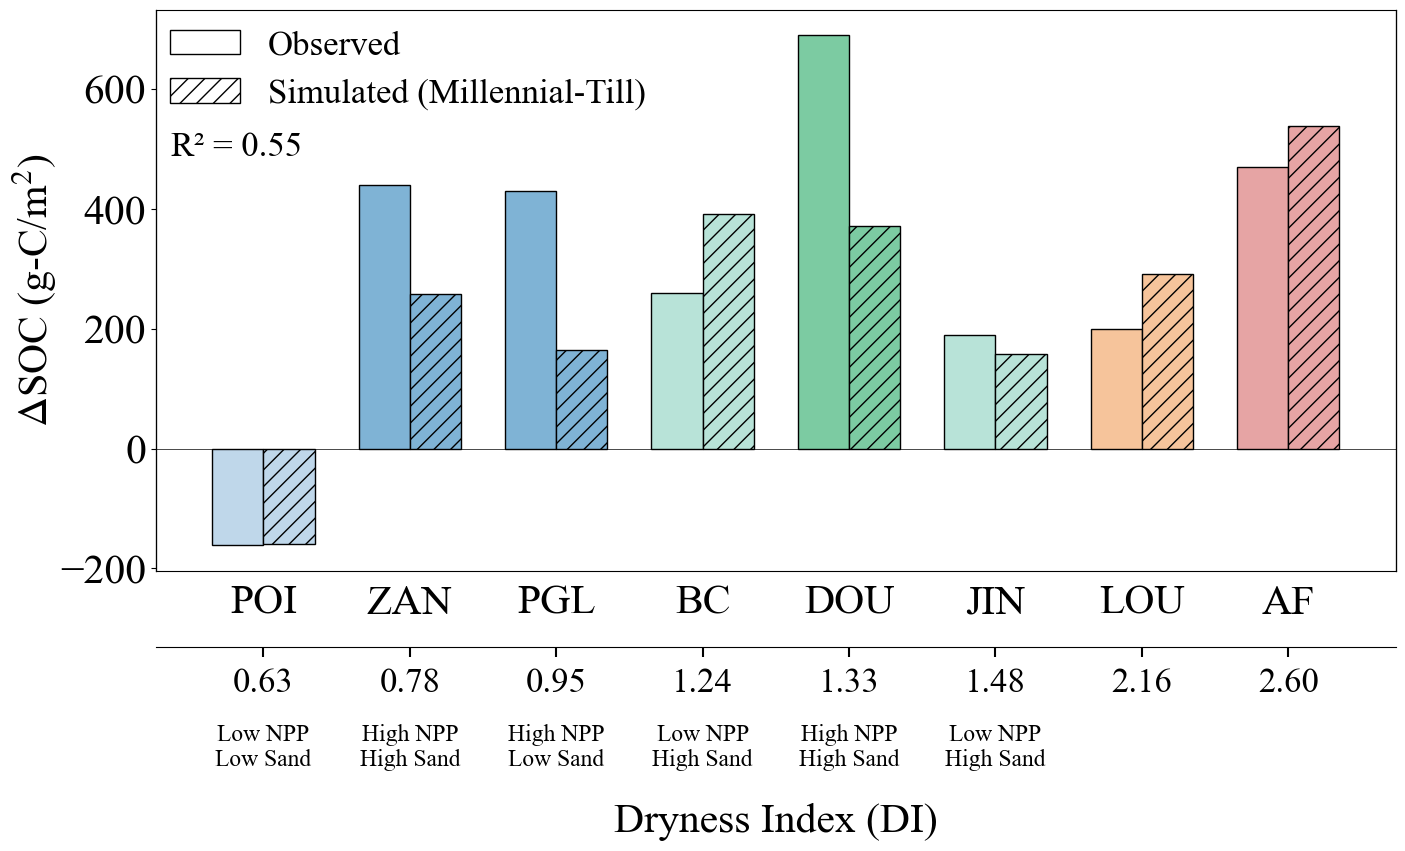

In [29]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from IPython.display import display

# =============================================================================
# CONFIG
# =============================================================================
folder_path = r'C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Final Testing (Revision)\Results'
obs_excel = os.path.join(folder_path, "gcb15001-sup-0001-tables1.xlsx")

study_files = ["AF_Test_Zr.csv", "BC_Test_Zr.csv", "DOU_Test_Zr.csv", "POI_Test_Zr.csv", "PGL_Test_Zr.csv", "ZAN_Test_Zr.csv", "JIN_Test_Zr.csv", "LOU_Test_Zr.csv"]
study_list = [f.replace("_Test_Zr.csv", "").strip().upper() for f in study_files]

study_colors = {
    "AF": "#E6A4A4",
    "BC": "#B8E3D8",
    "DOU": "#7CCBA2",
    "JIN": "#B8E3D8",
    "LOU": "#F6C49B",
    "POI": "#BFD7EA",
    "PGL": "#7FB3D5",
    "ZAN": "#7FB3D5"
}

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'stix'

# Default simulation windows
CT_START = 520
CT_END = 595
NT_START = 600

# =============================================================================
# STEP 1: LOAD OBSERVATIONS
# =============================================================================
obs_df = pd.read_excel(obs_excel, sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df["Study"] = obs_df["Study"].astype(str).str.strip().str.upper()
obs_df["Duration"] = pd.to_numeric(obs_df["Study Duration"], errors="coerce")

obs_df = obs_df[obs_df["Study"].isin(study_list)].copy()

# =============================================================================
# STEP 2: PROCESS SIMULATIONS
# =============================================================================
sim_results = []

for filename in study_files:
    study = filename.replace("_Test_Zr.csv", "").strip().upper()

    if study not in obs_df["Study"].values:
        print(f"Skipping {study}: Study not found in observations.")
        continue

    duration = int(obs_df.loc[obs_df["Study"] == study, "Duration"].values[0])

    # Assign study-specific CT and NT periods
    if study == "POI":
        ct_start, ct_end, nt_start = CT_START, CT_END, NT_START
    else:
        ct_start, ct_end, nt_start = CT_START, CT_END, NT_START

    end_year = nt_start + duration

    df = pd.read_csv(os.path.join(folder_path, filename))
    df["Year"] = pd.to_numeric(df["Years"], errors="coerce")
    df = df.dropna(subset=["Year"]).sort_values("Year")

    for c in ["A", "P", "DOC", "M", "B"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df["SOC"] = df[["A", "P", "DOC", "M", "B"]].sum(axis=1, min_count=5)
    df = df.dropna(subset=["SOC"])

    # ---- CT window ----
    ct_window = df.loc[df["Year"].between(ct_start, ct_end)]

    if ct_window.empty:
        print(f"Skipping {study}: No CT data between years {ct_start} and {ct_end}.")
        continue

    CT_SOC = ct_window["SOC"].mean()

    # ---- NT year ----
    if end_year in df["Year"].values:
        NT_SOC = df.loc[df["Year"] == end_year, "SOC"].values[0]
        nt_method = "Exact year"
    elif df["Year"].min() < end_year < df["Year"].max():
        NT_SOC = np.interp(end_year, df["Year"], df["SOC"])
        nt_method = "Interpolated"
    else:
        print(f"Skipping {study}: NT year {end_year} outside simulation range.")
        continue

    sim_results.append({
        "Study": study,
        "Duration": duration,
        "CT_Start": ct_start,
        "CT_End": ct_end,
        "NT_Year": end_year,
        "CT_SOC": CT_SOC,
        "NT_SOC": NT_SOC,
        "NT_Method": nt_method,
        "Simulated Delta SOC": NT_SOC - CT_SOC
    })

if not sim_results:
    raise ValueError("No valid simulation results were processed. Check study names, CSV files, and simulation years.")

sim_df = pd.DataFrame(sim_results)

# =============================================================================
# STEP 3: MERGE WITH OBSERVATIONS
# =============================================================================
merged_df = pd.merge(obs_df, sim_df, on=["Study", "Duration"], how="inner")

if merged_df.empty:
    raise ValueError("No matching observations and simulations were found.")

# =============================================================================
# STEP 4: R² CALCULATION
# =============================================================================
x = merged_df["Observed Delta SOC"].values.reshape(-1, 1)
y = merged_df["Simulated Delta SOC"].values

model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)
r2 = r2_score(y, y_pred)

print(f"\nRegression R² = {r2:.3f}")

# =============================================================================
# STEP 5: AI-BASED ORDERING
# =============================================================================
def assign_ai_bin(ai):
    if 0.5 <= ai < 1: return '[0.5-1)'
    elif 1 <= ai < 1.5: return '[1-1.5)'
    elif 1.5 <= ai < 2.5: return '[1.5-2.5)'
    elif 2.5 <= ai <= 4: return '[2.5-4)'
    else: return 'Out of range'

merged_df["AI Bin"] = merged_df["AI"].apply(assign_ai_bin)

merged_df["AI Bin"] = pd.Categorical(merged_df["AI Bin"], categories=['[0.5-1)', '[1-1.5)', '[1.5-2.5)', '[2.5-4)'], ordered=True)

merged_df = merged_df.sort_values(["AI Bin", "AI", "Study"]).reset_index(drop=True)

# =============================================================================
# STEP 6: SOC SUMMARY TABLE
# =============================================================================
summary_df = merged_df[["Study", "Duration", "CT_Start", "CT_End", "NT_Year", "CT_SOC", "NT_SOC", "Observed Delta SOC", "Simulated Delta SOC"]].copy()

summary_df.columns = ["Study", "Duration (yr)", "CT Start", "CT End", "NT Year", "CT SOC", "NT SOC", "Observed ΔSOC", "Simulated ΔSOC"]

print("\nSOC SUMMARY FOR ALL STUDIES (g-C/m²)")

display(summary_df.style.format({"CT SOC": "{:.2f}", "NT SOC": "{:.2f}", "Observed ΔSOC": "{:.2f}", "Simulated ΔSOC": "{:.2f}"}).hide(axis="index")
    .set_table_styles([{"selector": "th", "props": [("text-align", "center"), ("padding", "8px 15px")]}, {"selector": "td", "props": [("text-align", "center"), ("padding", "6px 15px")]}    ])
)

fig, ax = plt.subplots(figsize=(16, 11))
xpos = np.arange(len(merged_df))
width = 0.35

for i, row in merged_df.iterrows():
    color = study_colors.get(row["Study"], "#cccccc")
    ax.bar(xpos[i] - width/2, row["Observed Delta SOC"], width,
           color=color, edgecolor="black")
    ax.bar(xpos[i] + width/2, row["Simulated Delta SOC"], width,
           color=color, edgecolor="black", hatch="//")

ax.set_ylabel(r"$\Delta$SOC (g-C/m$^2$)", fontsize=30, labelpad=1)
ax.set_xticks(xpos)
ax.set_xticklabels(merged_df["Study"], fontsize=30)
ax.tick_params(axis="x", length=0, pad=10)
ax.tick_params(axis="y", labelsize=30)
ax.axhline(0, color="black", linewidth=0.5)

# Site information
di_values = {
    "POI": 0.63, "ZAN": 0.78, "PGL": 0.95, "BC": 1.24,
    "DOU": 1.33, "JIN": 1.48, "LOU": 2.16, "AF": 2.60
}

npp_values = {
    "POI": 456.25, "ZAN": 996.45, "PGL": 558.45,
    "BC": 492.75, "DOU": 737.3, "JIN": 419.8
}

sand_values = {
    "POI": 21, "ZAN": 54, "PGL": 25,
    "BC": 30, "DOU": 47, "JIN": 30
}

npp_threshold, sand_threshold = 550, 26

# Secondary x-axis: Dryness Index
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.xaxis.set_ticks_position("bottom")
ax2.xaxis.set_label_position("bottom")
ax2.spines["bottom"].set_position(("outward", 55))
ax2.spines["top"].set_visible(False)

ax2.set_xticks(xpos)
ax2.set_xticklabels([f"{di_values[s]:.2f}" for s in merged_df["Study"]],
                    fontsize=25, fontfamily="Times New Roman")
ax2.tick_params(axis="x", length=7, width=1.5, direction="out", pad=8)
ax2.set_xlabel("Dryness Index (DI)", fontsize=30, labelpad=75)

# Third x-axis: NPP and Sand classifications
ax3 = ax.twiny()
ax3.set_xlim(ax.get_xlim())
ax3.xaxis.set_ticks_position("bottom")
ax3.spines["bottom"].set_position(("outward", 105))
ax3.spines["bottom"].set_visible(False)
ax3.spines["top"].set_visible(False)

group_labels = []
for study in merged_df["Study"]:
    if study in npp_values:
        npp = "Low NPP" if npp_values[study] <= npp_threshold else "High NPP"
        sand = "Low Sand" if sand_values[study] <= sand_threshold else "High Sand"
        group_labels.append(f"{npp}\n{sand}")
    else:
        group_labels.append("")

ax3.set_xticks(xpos)
ax3.set_xticklabels(group_labels, fontsize=17, fontfamily="Times New Roman")
ax3.tick_params(axis="x", length=0, pad=5)

# Legend
legend_handles = [
    Patch(facecolor="white", edgecolor="black", label="Observed"),
    Patch(facecolor="white", edgecolor="black", hatch="//",
          label="Simulated (Millennial-Till)")
]

ax.legend(handles=legend_handles, fontsize=25, frameon=False,
          loc="upper right", bbox_to_anchor=(0.42, 1.02))

ax.text(0.012, 0.74, f"R² = {r2:.2f}", transform=ax.transAxes, fontsize=25, fontfamily="Times New Roman")

plt.subplots_adjust(bottom=0.37)
plt.show()

# Pools Change

In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
from IPython.display import display

# =============================================================================
# 1. CONFIGURATION
# =============================================================================
folder_path = r'C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Final Testing (Revision)\Results'

sites = ['AF', 'BC', 'DOU', 'POI', 'PGL', 'ZAN', 'JIN', 'LOU']
pools = {'A': 'A', 'P': 'P', 'DOC': 'DOC', 'MAOM': 'M', 'MB': 'B'}

CT_START, CT_END = 520, 595
NT_START = 600

study_colors = {
    'AF': '#E6A4A4', 'BC': '#B8E3D8', 'DOU': '#7CCBA2',
    'JIN': '#B8E3D8', 'LOU': '#F6C49B', 'POI': '#BFD7EA',
    'PGL': '#7FB3D5', 'ZAN': '#7FB3D5'
}

figsize = (12, 8)
label_fontsize = tick_fontsize = 30
bar_width = 0.6
pool_color = '#D9CECC'
save = False

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'stix'

# =============================================================================
# 2. OBSERVATIONS
# =============================================================================
obs_df = pd.read_excel(os.path.join(folder_path, 'gcb15001-sup-0001-tables1.xlsx'), sheet_name='SOC')
obs_df.columns = obs_df.columns.str.strip()
obs_df['Study'] = obs_df['Study'].str.strip().str.upper()
obs_df = obs_df.set_index('Study')

# =============================================================================
# 3. CALCULATE CT, NT AND POOL CHANGES
# =============================================================================
results = []

for study in sites:
    duration = int(obs_df.loc[study, 'Study Duration'])
    ai = float(obs_df.loc[study, 'AI'])
    nt_year = NT_START + duration

    df = pd.read_csv(os.path.join(folder_path, f'{study}_Test_Zr.csv'))
    df = df.sort_values('Years')

    # CT average between years 720-770
    ct = df[df['Years'].between(CT_START, CT_END)]

    row = {
        'Study': study, 'AI': ai, 'Duration': duration,
        'CT_Start': CT_START, 'CT_End': CT_END, 'NT_Year': nt_year
    }

    for pool, col in pools.items():
        ct_value = ct[col].mean()
        nt_value = np.interp(nt_year, df['Years'], df[col])

        row[f'CT_{pool}'] = ct_value
        row[f'NT_{pool}'] = nt_value
        row[f'DELTA_{pool}'] = nt_value - ct_value

    results.append(row)

pool_df = pd.DataFrame(results).sort_values('AI').reset_index(drop=True)

# =============================================================================
# 4. SUMMARY TABLE
# =============================================================================
summary_cols = ['Study', 'Duration', 'CT_Start', 'CT_End', 'NT_Year']

for pool in pools:
    summary_cols += [f'CT_{pool}', f'NT_{pool}', f'DELTA_{pool}']

print('\nCARBON POOL CHANGES (g-C/m²)')

display(
    pool_df[summary_cols].round(2).style
    .hide(axis='index')
    .set_properties(**{'text-align': 'center'})
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')]}
    ])
)


CARBON POOL CHANGES (g-C/m²)


Study,Duration,CT_Start,CT_End,NT_Year,CT_A,NT_A,DELTA_A,CT_P,NT_P,DELTA_P,CT_DOC,NT_DOC,DELTA_DOC,CT_MAOM,NT_MAOM,DELTA_MAOM,CT_MB,NT_MB,DELTA_MB
POI,13,520,595,613,1190.550000,1832.670000,642.120000,910.540000,142.320000,-768.220000,196.900000,198.940000,2.050000,3276.730000,3275.600000,-1.130000,204.400000,170.960000,-33.440000
ZAN,18,520,595,618,1270.050000,1822.970000,552.910000,375.160000,91.070000,-284.100000,216.150000,220.230000,4.080000,1037.410000,1038.130000,0.720000,155.210000,139.920000,-15.290000
PGL,8,520,595,608,1235.000000,1802.950000,567.950000,455.390000,98.420000,-356.980000,298.690000,305.840000,7.160000,4368.200000,4368.970000,0.760000,132.260000,77.110000,-55.150000
BC,9,520,595,609,1207.270000,1755.050000,547.780000,184.070000,38.330000,-145.740000,193.050000,195.560000,2.510000,1515.000000,1516.390000,1.400000,84.530000,70.770000,-13.760000
DOU,20,520,595,620,1208.000000,1809.460000,601.460000,278.840000,66.290000,-212.550000,565.650000,557.910000,-7.750000,1788.020000,1787.060000,-0.960000,94.760000,85.930000,-8.830000
JIN,6,520,595,606,988.160000,1545.740000,557.580000,354.140000,26.520000,-327.620000,208.170000,210.300000,2.130000,1304.880000,1291.700000,-13.190000,150.540000,88.720000,-61.810000
LOU,12,520,595,612,642.020000,1562.860000,920.840000,501.670000,28.130000,-473.530000,359.160000,292.270000,-66.890000,2255.770000,2238.580000,-17.190000,161.210000,90.030000,-71.180000
AF,11,520,595,611,703.250000,1750.830000,1047.580000,492.330000,62.270000,-430.060000,435.210000,385.390000,-49.820000,1789.390000,1781.670000,-7.720000,127.110000,105.530000,-21.580000


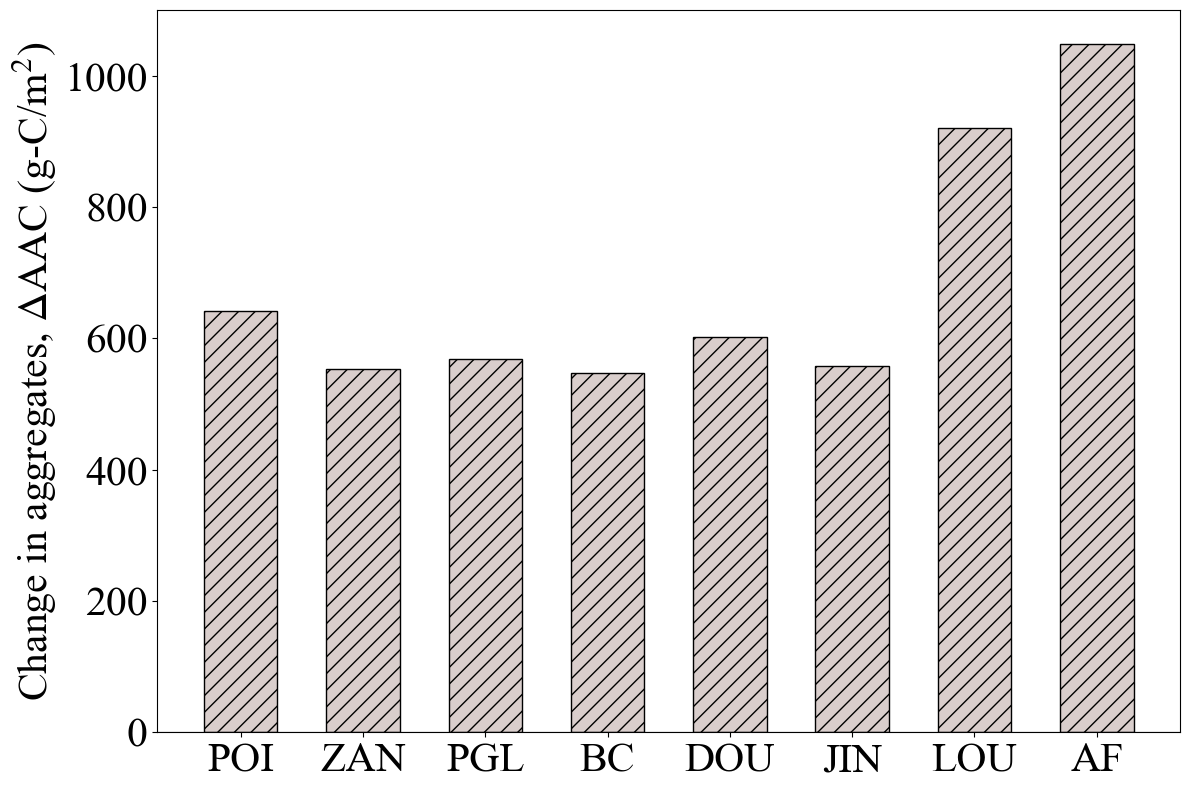

In [31]:
# =============================================================================
# CELL 4: CHANGE IN AGGREGATE-ASSOCIATED CARBON
# =============================================================================
x = np.arange(len(pool_df))
fig_A, ax = plt.subplots(figsize=figsize)

ax.bar(x, pool_df["DELTA_A"], width=bar_width,
       color=pool_color, edgecolor="black", hatch="//")

ax.set_ylabel(r"Change in aggregates, $\Delta$AAC (g-C/m$^2$)", fontsize=label_fontsize)
ax.set_xticks(x)
ax.set_xticklabels(pool_df["Study"], fontsize=tick_fontsize)
ax.tick_params(axis="y", labelsize=tick_fontsize)
ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

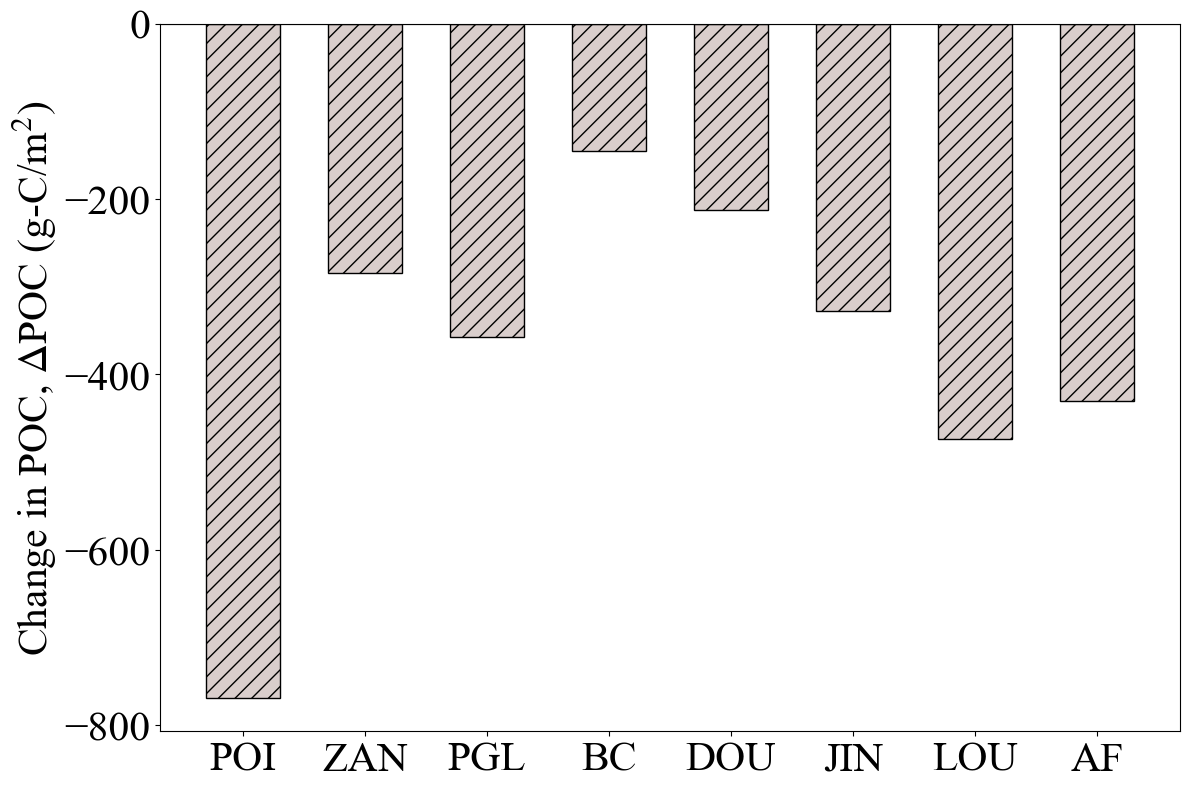

In [32]:
# =============================================================================
# CELL 5: CHANGE IN PARTICULATE ORGANIC CARBON
# =============================================================================
x = np.arange(len(pool_df))
fig_P, ax = plt.subplots(figsize=figsize)

ax.bar(x, pool_df["DELTA_P"], width=bar_width,
       color=pool_color, edgecolor="black", hatch="//")

ax.set_ylabel(r"Change in POC, $\Delta$POC (g-C/m$^2$)", fontsize=label_fontsize)
ax.set_xticks(x)
ax.set_xticklabels(pool_df["Study"], fontsize=tick_fontsize)
ax.tick_params(axis="y", labelsize=tick_fontsize)
ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

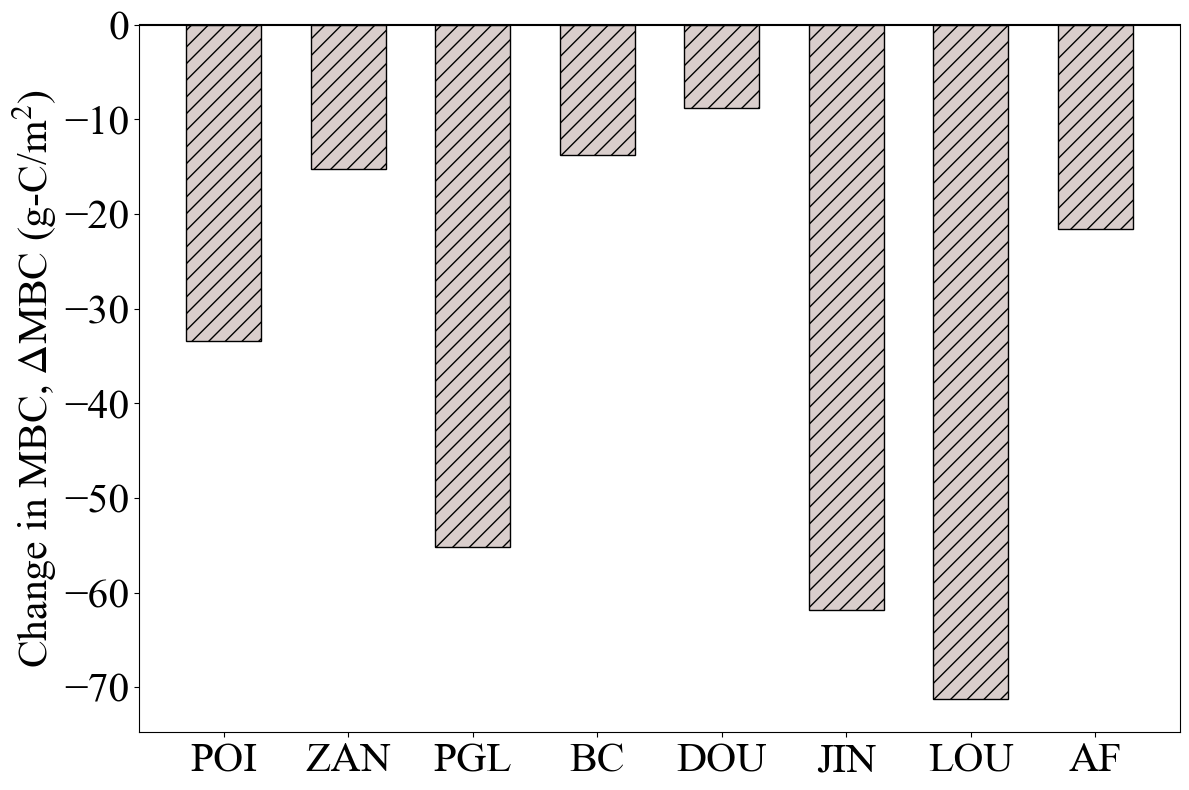

In [33]:
# =============================================================================
# CELL 6: CHANGE IN MICROBIAL BIOMASS CARBON
# =============================================================================
x = np.arange(len(pool_df))
fig_MB, ax = plt.subplots(figsize=figsize)

ax.bar(x, pool_df["DELTA_MB"], width=bar_width,
       color=pool_color, edgecolor="black", hatch="//")

ax.set_ylabel(r"Change in MBC, $\Delta$MBC (g-C/m$^2$)", fontsize=label_fontsize)
ax.set_xticks(x)
ax.set_xticklabels(pool_df["Study"], fontsize=tick_fontsize)
ax.tick_params(axis="y", labelsize=tick_fontsize)
ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

,Study,DI,Sand,NPP
0,POI,0.63,21,456.3
1,ZAN,0.78,54,996.5
2,PGL,0.95,25,560.0
3,BC,1.24,30,492.8
4,DOU,1.33,47,737.3
5,JIN,1.48,30,419.8
6,LOU,2.16,36,306.6
7,AF,2.60,38,485.5


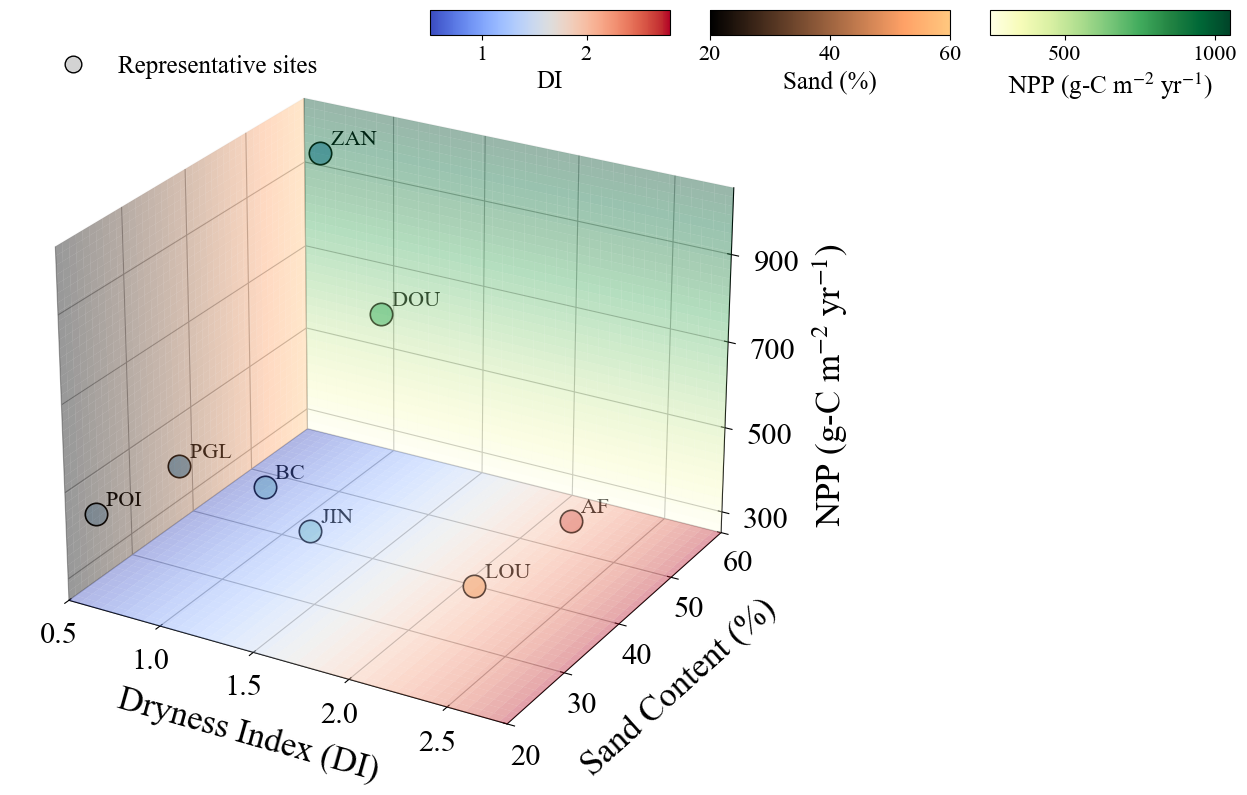

In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
from IPython.display import display

%matplotlib inline

# Configuration
colors = {"AF":"#E6A4A4","BC":"#B8E3D8","DOU":"#7CCBA2","JIN":"#B8E3D8","LOU":"#F6C49B","POI":"#BFD7EA","PGL":"#7FB3D5","ZAN":"#7FB3D5"}
di = {"POI":0.63,"ZAN":0.78,"PGL":0.95,"BC":1.24,"DOU":1.33,"JIN":1.48,"LOU":2.16,"AF":2.60}
sand = {"POI":21,"ZAN":54,"PGL":25,"BC":30,"DOU":47,"JIN":30,"LOU":36,"AF":38}
npp = {"POI":456.3,"ZAN":996.5,"PGL":560.0,"BC":492.8,"DOU":737.3,"JIN":419.8,"LOU":306.6,"AF":485.5}
PLANE_ALPHA, LEGEND_Y = 0.40, 0.99
mpl.rcParams.update({"font.family":"Times New Roman","mathtext.fontset":"stix"})

# Data
df = pd.DataFrame({"Study":list(di.keys())})
df["DI"] = df["Study"].map(di)
df["Sand"] = df["Study"].map(sand)
df["NPP"] = df["Study"].map(npp)
df = df.sort_values("DI").reset_index(drop=True)
display(df.round(2))

# Colormaps
di_cmap = mpl.colormaps["coolwarm"]
sand_cmap = mpl.colormaps["copper"]
npp_cmap = mpl.colormaps["YlGn"]

# Figure
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, projection="3d")
ax.set_position([0.05,0.08,0.72,0.76])

xmin, xmax = 0.5, 2.8
ymin, ymax = 20, 60
zmin, zmax = 250, 1050

# DI plane on floor
Xf, Yf = np.meshgrid(np.linspace(xmin,xmax,120), np.linspace(ymin,ymax,40))
Zf = np.full_like(Xf, zmin)
Cf = di_cmap((Xf - xmin) / (xmax - xmin))
ax.plot_surface(Xf, Yf, Zf, facecolors=Cf, alpha=PLANE_ALPHA, shade=False, edgecolor="none")

# Sand plane on left wall
Ys, Zs = np.meshgrid(np.linspace(ymin,ymax,120), np.linspace(zmin,zmax,40))
Xs = np.full_like(Ys, xmin)
Cs = sand_cmap((Ys - ymin) / (ymax - ymin))
ax.plot_surface(Xs, Ys, Zs, facecolors=Cs, alpha=PLANE_ALPHA, shade=False, edgecolor="none")

# NPP plane on back wall
Xn, Zn = np.meshgrid(np.linspace(xmin,xmax,120), np.linspace(zmin,zmax,40))
Yn = np.full_like(Xn, ymax)
Cn = npp_cmap((Zn - zmin) / (zmax - zmin))
ax.plot_surface(Xn, Yn, Zn, facecolors=Cn, alpha=PLANE_ALPHA, shade=False, edgecolor="none")

# Site markers
for _, r in df.iterrows():
    d, s, n, c = r["DI"], r["Sand"], r["NPP"], colors[r["Study"]]
    ax.scatter(d, s, n, s=260, marker="o", color=c, edgecolor="black", linewidth=1.2, depthshade=False)
    ax.text(d, s, n+18, f"  {r['Study']}", fontsize=16)

# Formatting
ax.set_xlabel("Dryness Index (DI)", fontsize=25, labelpad=18)
ax.set_ylabel("Sand Content (%)", fontsize=25, labelpad=18)
ax.set_zlabel("")
fig.text(0.63,0.48,r"NPP (g-C m$^{-2}$ yr$^{-1}$)", fontsize=25, rotation=90, va="center", ha="center")

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_zlim(zmin, zmax)
ax.set_xticks(np.arange(0.5, 2.81, 0.5))
ax.set_yticks(np.arange(20, 61, 10))
ax.set_zticks(np.arange(300, 1001, 200))
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=22)
ax.tick_params(axis="z", labelsize=22, pad=12)
ax.view_init(elev=25, azim=-60)
ax.set_box_aspect((1.3, 1.2, 1))
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]: axis.pane.fill = False
ax.grid(True)

# Site legend
legend = [Line2D([0],[0], marker="o", color="w", markerfacecolor="lightgray", markeredgecolor="black", markersize=12, label="Representative sites")]
ax.legend(handles=legend, fontsize=18, frameon=False, loc="upper left", bbox_to_anchor=(0.02, LEGEND_Y))

# Top horizontal colorbars in one row
cax1 = fig.add_axes([0.43,0.83,0.12,0.025])
cb1 = plt.colorbar(ScalarMappable(norm=mpl.colors.Normalize(vmin=xmin, vmax=xmax), cmap=di_cmap), cax=cax1, orientation="horizontal")
cb1.set_label("DI", fontsize=18, labelpad=4)
cb1.ax.tick_params(labelsize=16)

cax2 = fig.add_axes([0.57,0.83,0.12,0.025])
cb2 = plt.colorbar(ScalarMappable(norm=mpl.colors.Normalize(vmin=ymin, vmax=ymax), cmap=sand_cmap), cax=cax2, orientation="horizontal")
cb2.set_label("Sand (%)", fontsize=18, labelpad=4)
cb2.ax.tick_params(labelsize=16)

cax3 = fig.add_axes([0.71,0.83,0.12,0.025])
cb3 = plt.colorbar(ScalarMappable(norm=mpl.colors.Normalize(vmin=zmin, vmax=zmax), cmap=npp_cmap), cax=cax3, orientation="horizontal")
cb3.set_label(r"NPP (g-C m$^{-2}$ yr$^{-1}$)", fontsize=18, labelpad=4)
cb3.ax.tick_params(labelsize=16)

plt.show()